In [1]:
from __future__ import print_function
import os
import cv2 
import numpy as np
import pandas as pd   
import matplotlib.pyplot as plt
from PIL import Image
from pillow_heif import register_heif_opener
import random
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.model_selection import KFold, cross_val_score, cross_validate
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold
from skimage.feature import local_binary_pattern
import warnings
import mahotas
warnings.filterwarnings("ignore")

In [2]:
GROUP = "C7"
DTYPE="CMMS"
DIR_TRAIN = "DATA/TRAINING/"
GROUP_path = DIR_TRAIN+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path = os.listdir(GROUP_path)
resume = []
data_path = []
for HH in HH_path:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT = pd.DataFrame(resume)    # values
pdDT.columns = ["Humidity", "numberImages", "pathImages"]
pdDT

,Humidity,numberImages,pathImages
0,C7_10,28,"[DATA/TRAINING/C7/C7_10/IMG_8189.HEIC, DATA/TR..."
1,C7_11,27,"[DATA/TRAINING/C7/C7_11/IMG_8248.HEIC, DATA/TR..."
2,C7_12,25,"[DATA/TRAINING/C7/C7_12/IMG_8280.HEIC, DATA/TR..."
3,C7_13,25,"[DATA/TRAINING/C7/C7_13/IMG_8311.HEIC, DATA/TR..."
4,C7_14,25,"[DATA/TRAINING/C7/C7_14/IMG_8406.HEIC, DATA/TR..."
5,C7_15,25,"[DATA/TRAINING/C7/C7_15/IMG_8343.HEIC, DATA/TR..."
6,C7_16,27,"[DATA/TRAINING/C7/C7_16/IMG_8375.HEIC, DATA/TR..."


In [3]:
def read_imgHEIC(pic_path):
    register_heif_opener(); im = Image.open(pic_path)
    return cv2.cvtColor(np.array(im), cv2.COLOR_RGB2BGR)

In [4]:
def flip_image_vertical(image):
    height, width, channels = image.shape
    if(height < width):
        image = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)
    return image

In [5]:
def resize_image(img, scale_percent = 10):
     # percent of original size
    width = int(img.shape[1] * scale_percent / 100)
    height = int(img.shape[0] * scale_percent / 100)
    dim = (width, height)
    #print(dim)
    # resize image
    resized = cv2.resize(img, dim, interpolation = cv2.INTER_AREA)
    return resized

Text(0.5, 1.0, '16% IMG_8388.HEIC')

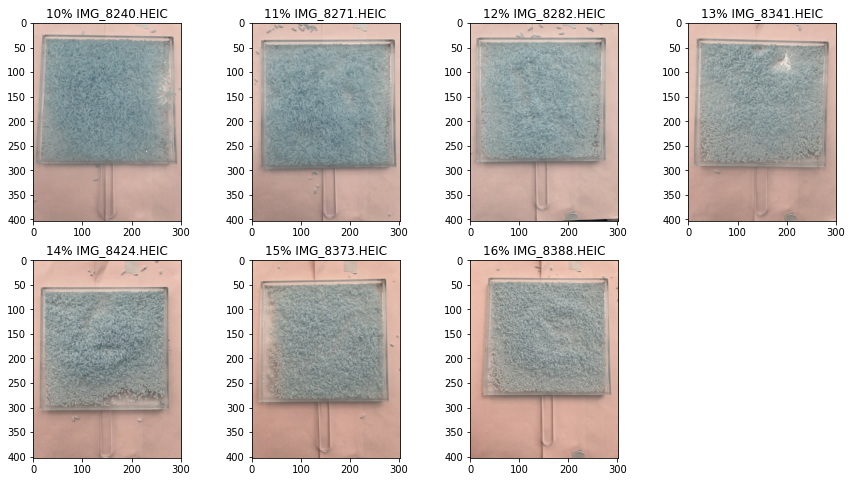

In [6]:
fig=plt.figure(figsize=(15, 8)) 
ax1 = fig.add_subplot(2,4,1); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[0][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax1.imshow(image); ax1.set_title("10% " + data_path[0][path_image].split("/")[4])
ax2 = fig.add_subplot(2,4,2); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[1][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax2.imshow(image); ax2.set_title("11% "+ data_path[1][path_image].split("/")[4])
ax3 = fig.add_subplot(2,4,3); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[2][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax3.imshow(image); ax3.set_title("12% "+ data_path[2][path_image].split("/")[4])
ax4 = fig.add_subplot(2,4,4); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[3][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax4.imshow(image); ax4.set_title("13% "+ data_path[3][path_image].split("/")[4])
ax5 = fig.add_subplot(2,4,5); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[4][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax5.imshow(image); ax5.set_title("14% "+ data_path[4][path_image].split("/")[4])
ax6 = fig.add_subplot(2,4,6); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[5][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax6.imshow(image); ax6.set_title("15% "+ data_path[5][path_image].split("/")[4])
ax7 = fig.add_subplot(2,4,7); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[6][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax7.imshow(image); ax7.set_title("16% "+ data_path[6][path_image].split("/")[4])

In [7]:
def color_moments(image):
    # Split the channels - h,s,v
    h, s, v = cv2.split(image)
    # Initialize the color feature
    color_feature = []
    # N = h.shape[0] * h.shape[1]
    
    # The first central moment - average
    h_mean = np.mean(h)  # np.sum(h)/float(N)
    s_mean = np.mean(s)  # np.sum(s)/float(N)
    v_mean = np.mean(v)  # np.sum(v)/float(N)
    color_feature.extend([h_mean, s_mean, v_mean])
    
    # The second central moment - standard deviation
    h_std = np.std(h)  # np.sqrt(np.mean(abs(h - h.mean())**2))
    s_std = np.std(s)  # np.sqrt(np.mean(abs(s - s.mean())**2))
    v_std = np.std(v)  # np.sqrt(np.mean(abs(v - v.mean())**2))
    color_feature.extend([h_std, s_std, v_std])
    
    # The third central moment - the third root of the skewness
    h_skewness = np.mean(abs(h - h.mean())**3)
    s_skewness = np.mean(abs(s - s.mean())**3)
    v_skewness = np.mean(abs(v - v.mean())**3)
    h_thirdMoment = h_skewness**(1./3)
    s_thirdMoment = s_skewness**(1./3)
    v_thirdMoment = v_skewness**(1./3)
    color_feature.extend([h_thirdMoment, s_thirdMoment, v_thirdMoment])
    """
    # The second central moment - standard deviation
    hist_h = cv2.calcHist([h], [0], None, [256], [0, 256])
    hist_h = cv2.normalize(hist_h, hist_h, 0, 1, cv2.NORM_MINMAX)

    hist_s = cv2.calcHist([s], [0], None, [256], [0, 256])
    hist_s = cv2.normalize(hist_s, hist_s, 0, 1, cv2.NORM_MINMAX)

    hist_v = cv2.calcHist([v], [0], None, [256], [0, 256])
    hist_v = cv2.normalize(hist_v, hist_v, 0, 1, cv2.NORM_MINMAX)

    h_skew = kurtosis(hist_h)  
    s_skew = kurtosis(hist_s) 
    v_skew = kurtosis(hist_v) 
    color_feature.extend([h_skew[0], s_skew[0], v_skew[0]])
    
    
    h_kts = kurtosis(hist_h)  
    s_kts = kurtosis(hist_s) 
    v_kts = kurtosis(hist_v) 
    color_feature.extend([h_kts[0], s_kts[0], v_kts[0]])
    
    # The second central moment - standard deviation
    h_ent = entropy(hist_h)  
    s_ent = entropy(hist_s) 
    v_ent = entropy(hist_v) 
    color_feature.extend([h_ent, s_ent, v_ent])
    """
    return color_feature

In [153]:
#Parameters
HH = ['10', '11', '12', '13', '14', '15', '16']
#bins=44; #width=2024; height=3032; 
scale=25
dtHH=[]
for lstImgs, H in zip(data_path, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        #print(image.shape)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

        features = color_moments(hsv)
        arr_img_hist.append(features)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH.append(pdGrayFeatures)

In [154]:
result = pd.concat(dtHH)

DIR= "FEATURES/ORIGINAL/GLOBAL/TRAINING/"; 
result.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result.head(10)

,0,1,2,3,4,5,6,7,8,scale,height,width,channels,IMAGENAME,HUMIDITY
0,76.549711,38.648506,183.729547,40.699589,16.981779,31.216435,41.508485,18.306079,34.179810,25,1008,756,3,IMG_8189.HEIC,10
1,74.251650,39.894395,174.869960,41.305396,18.153908,33.514956,41.850437,19.636560,37.344191,25,1008,756,3,IMG_8190.HEIC,10
2,73.629664,43.000613,176.251331,42.681074,15.708935,32.962658,43.169160,18.436258,36.745434,25,1008,756,3,IMG_8193.HEIC,10
3,68.493343,41.931612,173.602496,42.885050,15.787794,31.195875,43.101719,18.439338,35.513257,25,1008,756,3,IMG_8194.HEIC,10
4,69.778757,36.183865,181.055186,41.486943,13.924003,28.536733,41.732913,16.706799,33.264509,25,1008,756,3,IMG_8199.HEIC,10
5,67.786200,41.126753,175.551408,42.996368,15.549642,31.433242,43.267649,18.125833,35.404359,25,1008,756,3,IMG_8206.HEIC,10
6,68.405619,41.130215,177.321320,42.657313,15.281282,31.150128,42.932118,17.841225,34.284122,25,1008,756,3,IMG_8210.HEIC,10
7,68.608530,39.425136,179.788942,41.643974,17.090431,30.725643,41.949491,24.360541,36.065323,25,1008,756,3,IMG_8211.HEIC,10
8,69.165371,39.664634,172.348966,42.190378,16.658552,30.431147,42.465568,18.866955,34.278008,25,1008,756,3,IMG_8215.HEIC,10
9,72.322423,39.767307,180.299607,41.399883,16.619802,31.434034,41.800037,20.113938,35.197761,25,1008,756,3,IMG_8216.HEIC,10


# Classification

In [155]:
dtFeatures=result#.drop(['IMAGENAME'], axis=1)
#dtFeatures.head()
X = dtFeatures.values[:, :-6]
#X

In [156]:

# Normalization -> values[0-1]
scaler = MinMaxScaler()
X_scale = scaler.fit_transform(X)     
y = dtFeatures.values[:, -1]
#y

In [157]:
def compute_classification_metrics(y_pred, y_test):
    acc = np.sum(y_pred == y_test) / float(len(y_test))
    precision =np.mean(precision_score(y_test, y_pred, average=None, zero_division=1))
    recall =np.mean(recall_score(y_test, y_pred, average=None, zero_division=1))
    F1 = 2 * (precision * recall) / (precision + recall)
    return acc, precision, recall, F1

In [158]:
def get_CV_CLASSIFICATION_MODELS(model, X, y, rescale=False):
    dt_lg_test=[]  
    if rescale==True:
        y=y-10
        #print(y)
    kfold = StratifiedKFold(n_splits=10, shuffle=True)
    k_fold=1
    for train_index , test_index in kfold.split(X, y):

        X_train , X_test = X[train_index], X[test_index]
        y_train , y_test = y[train_index], y[test_index]
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)  # predict label

        [acc, precision, recall, F1] = compute_classification_metrics(y_pred, y_test)
        dt_lg_test.append([k_fold, acc, precision, recall, F1])
        k_fold=k_fold+1
    return dt_lg_test

#### Random Forest Classifier

In [159]:
modelRFC=RandomForestClassifier(n_estimators=1000) 
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelRFC, X_scale, y)
modelName="RF_C"

In [160]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.789474,0.821429,0.809524,0.815433,CMMS,C7,RF_C,25,1008,756,3
1,2,0.578947,0.580952,0.595238,0.588008,CMMS,C7,RF_C,25,1008,756,3
2,3,0.500000,0.580952,0.523810,0.550903,CMMS,C7,RF_C,25,1008,756,3
3,4,0.666667,0.783333,0.690476,0.733980,CMMS,C7,RF_C,25,1008,756,3
4,5,0.611111,0.678571,0.619048,0.647444,CMMS,C7,RF_C,25,1008,756,3
5,6,0.611111,0.678571,0.619048,0.647444,CMMS,C7,RF_C,25,1008,756,3
6,7,0.444444,0.452381,0.404762,0.427249,CMMS,C7,RF_C,25,1008,756,3
7,8,0.833333,0.869048,0.833333,0.850816,CMMS,C7,RF_C,25,1008,756,3
8,9,0.833333,0.892857,0.833333,0.862069,CMMS,C7,RF_C,25,1008,756,3
9,10,0.666667,0.702381,0.642857,0.671302,CMMS,C7,RF_C,25,1008,756,3


In [161]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()
#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultRF=result
resultRF

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,CMMS,C7,RF_C,0.653509,0.657143,0.679465,0.704048


### MLP Classifier

In [162]:
# Import MLPClassifer 
from sklearn.neural_network import MLPClassifier

In [163]:
modelMLPC = MLPClassifier(max_iter=500)
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelMLPC, X_scale, y)
modelName='MLP_C'

In [164]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.421053,0.461905,0.404762,0.431450,CMMS,C7,MLP_C,25,1008,756,3
1,2,0.578947,0.640476,0.619048,0.629580,CMMS,C7,MLP_C,25,1008,756,3
2,3,0.555556,0.642857,0.595238,0.618132,CMMS,C7,MLP_C,25,1008,756,3
3,4,0.444444,0.537415,0.452381,0.491245,CMMS,C7,MLP_C,25,1008,756,3
4,5,0.444444,0.642857,0.476190,0.547112,CMMS,C7,MLP_C,25,1008,756,3
5,6,0.555556,0.692177,0.500000,0.580599,CMMS,C7,MLP_C,25,1008,756,3
6,7,0.555556,0.535714,0.523810,0.529695,CMMS,C7,MLP_C,25,1008,756,3
7,8,0.500000,0.630952,0.452381,0.526949,CMMS,C7,MLP_C,25,1008,756,3
8,9,0.500000,0.678571,0.500000,0.575758,CMMS,C7,MLP_C,25,1008,756,3
9,10,0.555556,0.550000,0.523810,0.536585,CMMS,C7,MLP_C,25,1008,756,3


In [165]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,CMMS,C7,MLP_C,0.511111,0.504762,0.546711,0.601293


### XGBoost Classifier

In [166]:
modelXGBC = xgb.XGBClassifier()
y = np.array([int(x) for x in y])
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelXGBC, X_scale, y, True)
modelName='XGB_C'

In [167]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.526316,0.535714,0.523810,0.529695,CMMS,C7,XGB_C,25,1008,756,3
1,2,0.684211,0.704762,0.666667,0.685185,CMMS,C7,XGB_C,25,1008,756,3
2,3,0.666667,0.835034,0.642857,0.726451,CMMS,C7,XGB_C,25,1008,756,3
3,4,0.555556,0.595238,0.595238,0.595238,CMMS,C7,XGB_C,25,1008,756,3
4,5,0.333333,0.345238,0.333333,0.339181,CMMS,C7,XGB_C,25,1008,756,3
5,6,0.555556,0.464286,0.523810,0.492255,CMMS,C7,XGB_C,25,1008,756,3
6,7,0.833333,0.880952,0.833333,0.856481,CMMS,C7,XGB_C,25,1008,756,3
7,8,0.666667,0.740476,0.642857,0.688222,CMMS,C7,XGB_C,25,1008,756,3
8,9,0.444444,0.500000,0.428571,0.461538,CMMS,C7,XGB_C,25,1008,756,3
9,10,0.777778,0.773810,0.761905,0.767811,CMMS,C7,XGB_C,25,1008,756,3


In [168]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,CMMS,C7,XGB_C,0.604386,0.595238,0.614206,0.637551


# External validation

In [169]:
DIR_TEST = "DATA/TEST/"
GROUP_path = DIR_TEST+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path_test = os.listdir(GROUP_path)
resume = []
data_path_test = []
for HH in HH_path_test:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path_test.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT_test = pd.DataFrame(resume)    # values
pdDT_test.columns = ["Humidity", "numberImages", "pathImages"]
pdDT_test

,Humidity,numberImages,pathImages
0,C7_10,5,"[DATA/TEST/C7/C7_10/IMG_8188.HEIC, DATA/TEST/C..."
1,C7_11,5,"[DATA/TEST/C7/C7_11/IMG_8249.HEIC, DATA/TEST/C..."
2,C7_12,5,"[DATA/TEST/C7/C7_12/IMG_8279.HEIC, DATA/TEST/C..."
3,C7_13,5,"[DATA/TEST/C7/C7_13/IMG_8316.HEIC, DATA/TEST/C..."
4,C7_14,5,"[DATA/TEST/C7/C7_14/IMG_8411.HEIC, DATA/TEST/C..."
5,C7_15,5,"[DATA/TEST/C7/C7_15/IMG_8344.HEIC, DATA/TEST/C..."
6,C7_16,5,"[DATA/TEST/C7/C7_16/IMG_8377.HEIC, DATA/TEST/C..."


In [170]:
HH=['10', '11', '12', '13', '14', '15', '16']

In [171]:
dtHH_test=[]
for lstImgs, H in zip(data_path_test, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
        features = color_moments(hsv)
        arr_img_hist.append(features)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH_test.append(pdGrayFeatures)

In [172]:
result_test = pd.concat(dtHH_test)

DIR= "FEATURES/ORIGINAL/GLOBAL/TESTING/"; 
result_test.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result_test.head(10)

,0,1,2,3,4,5,6,7,8,scale,height,width,channels,IMAGENAME,HUMIDITY
0,75.968506,38.888655,182.067155,40.790789,17.153497,31.919680,41.525874,18.495173,34.913639,25,1008,756,3,IMG_8188.HEIC,10
1,67.982718,38.430264,171.710258,41.785553,15.905755,31.984859,42.090254,17.733082,36.045287,25,1008,756,3,IMG_8198.HEIC,10
2,69.773911,41.626331,172.330386,42.305126,14.601360,30.980180,42.480889,16.858974,34.525201,25,1008,756,3,IMG_8202.HEIC,10
3,66.481656,40.471709,179.128269,42.517224,15.188887,31.431855,42.809293,17.503431,35.046198,25,1008,756,3,IMG_8203.HEIC,10
4,71.641687,41.900630,179.916820,42.257853,16.176346,31.395045,42.589710,23.551509,36.215897,25,1008,756,3,IMG_8207.HEIC,10
0,79.653975,42.256139,177.725746,40.451158,23.903162,31.884157,41.941334,39.788315,37.442035,25,1008,756,3,IMG_8249.HEIC,11
1,72.830366,42.028664,173.283116,41.641224,16.660989,33.284910,42.073101,18.791391,37.044770,25,1008,756,3,IMG_8251.HEIC,11
2,74.029154,42.467981,173.627508,41.911733,16.488775,32.640755,42.418432,18.732050,36.619563,25,1008,756,3,IMG_8252.HEIC,11
3,69.988324,42.077688,175.340165,41.331121,15.278179,31.410826,41.610857,18.051387,35.103809,25,1008,756,3,IMG_8264.HEIC,11
4,72.975159,39.992247,174.415491,41.499097,15.338819,31.213077,41.915774,17.356061,34.804819,25,1008,756,3,IMG_8272.HEIC,11


In [173]:
dtFeaturesTest=result_test#.drop(['IMAGENAME'], axis=1)
#dtFeaturesTest.head()

In [174]:
X_test = dtFeaturesTest.values[:, :-6]
#X_test

In [175]:
X_test_scale = scaler.transform(X_test)     
y_test = dtFeaturesTest.values[:, -1]
y_test

array(['10', '10', '10', '10', '10', '11', '11', '11', '11', '11', '12',
       '12', '12', '12', '12', '13', '13', '13', '13', '13', '14', '14',
       '14', '14', '14', '15', '15', '15', '15', '15', '16', '16', '16',
       '16', '16'], dtype=object)

## RFC

In [176]:
y_pred = modelRFC.predict(X_test_scale)  # predict label

In [177]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.50      0.40      0.44         5
     Class 1       0.60      0.60      0.60         5
     Class 2       0.83      1.00      0.91         5
     Class 3       1.00      0.80      0.89         5
     Class 4       0.71      1.00      0.83         5
     Class 5       1.00      0.60      0.75         5
     Class 6       0.83      1.00      0.91         5

    accuracy                           0.77        35
   macro avg       0.78      0.77      0.76        35
weighted avg       0.78      0.77      0.76        35



## MLP

In [178]:
y_pred = modelMLPC.predict(X_test_scale)  # predict label

In [179]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.50      0.60      0.55         5
     Class 1       0.67      0.40      0.50         5
     Class 2       0.80      0.80      0.80         5
     Class 3       0.80      0.80      0.80         5
     Class 4       0.50      1.00      0.67         5
     Class 5       1.00      0.20      0.33         5
     Class 6       0.80      0.80      0.80         5

    accuracy                           0.66        35
   macro avg       0.72      0.66      0.64        35
weighted avg       0.72      0.66      0.64        35



## XGBC

In [180]:
y_pred = modelXGBC.predict(X_test_scale) 

In [181]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
y_test = np.array([int(x) for x in y_test])
res = classification_report(y_test-10, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.80      0.80      0.80         5
     Class 1       0.80      0.80      0.80         5
     Class 2       1.00      1.00      1.00         5
     Class 3       1.00      0.80      0.89         5
     Class 4       0.62      1.00      0.77         5
     Class 5       1.00      0.40      0.57         5
     Class 6       0.83      1.00      0.91         5

    accuracy                           0.83        35
   macro avg       0.87      0.83      0.82        35
weighted avg       0.87      0.83      0.82        35

